参考：https://zhuanlan.zhihu.com/p/49035741
https://seaborn.pydata.org/examples/index.html

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# 在Jupyter 中正常显示图形
%matplotlib inline
titanic = pd.read_csv('./titanic.csv')
titanic.sample(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
776,0,3,male,NaN,0,0,7.7500,Q,Third,man,True,F,Queenstown,no,True
95,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
537,1,1,female,30.0,0,0,106.4250,C,First,woman,False,NaN,Cherbourg,yes,True
473,1,2,female,23.0,0,0,13.7917,C,Second,woman,False,D,Cherbourg,yes,True
63,0,3,male,4.0,3,2,27.9000,S,Third,child,False,NaN,Southampton,no,False
179,0,3,male,36.0,0,0,0.0000,S,Third,man,True,NaN,Southampton,no,True
876,0,3,male,20.0,0,0,9.8458,S,Third,man,True,NaN,Southampton,no,True
875,1,3,female,15.0,0,0,7.2250,C,Third,child,False,NaN,Cherbourg,yes,True
44,1,3,female,19.0,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True
698,0,1,male,49.0,1,1,110.8833,C,First,man,True,C,Cherbourg,no,False


## 1. 条形图

利用矩阵条的高度反映数值变量的集中趋势

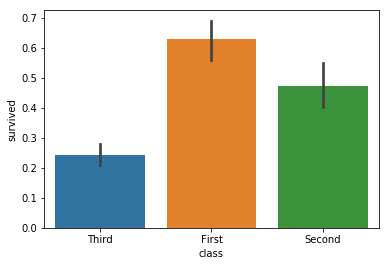

In [21]:
# barplot 表示输出条形图
sns.barplot(x='class',y='survived',data=titanic)

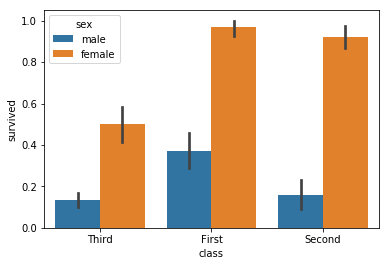

In [ ]:
# 对x轴的数据进行细分，细分的条件就是'hue'的参数值
sns.barplot(x='class',y='survived',hue='sex',data=titanic)

## 2. 直方图

变量的分布规律

c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "


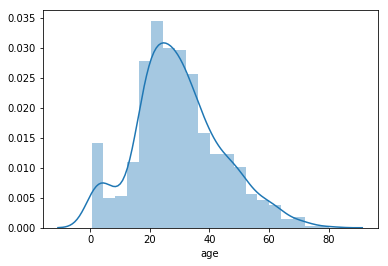

In [13]:
#去除'age'中的缺失值，distplot不能处理缺失数据
age1=titanic['age'].dropna()
sns.distplot(age1)

c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "


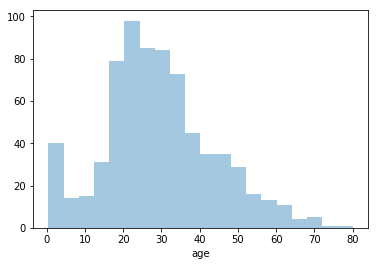

In [15]:
#去掉拟合的密度估计曲线，kde参数设为False
sns.distplot(age1,kde=False)

c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "


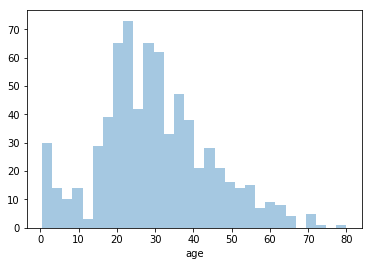

In [16]:
# 通过'bins'参数设定数据片段的数量
sns.distplot(age1,bins=30,kde=False)

c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "
c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "


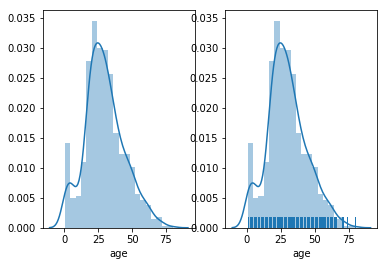

In [18]:
#创建一个一行2列的画布,主要方便对比
fig,axes=plt.subplots(1,2)

#设置'reg'参数，加上观测数值的边际毛毯
#需要用axes[]表示是第几张图，从0开始
sns.distplot(age1,ax=axes[0]) #左图
sns.distplot(age1,rug=True,ax=axes[1]) #右图

c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "
c:\ProgramData\Anaconda3\lib\site-packages\matplotlib\axes\_axes.py:6462: UserWarning: The 'normed' kwarg is deprecated, and has been replaced by the 'density' kwarg.
  warnings.warn("The 'normed' kwarg is deprecated, and has been "


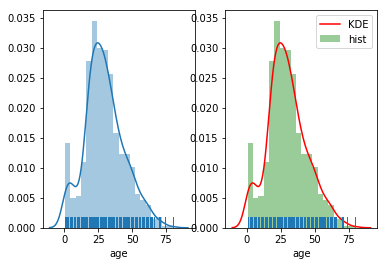

In [20]:
#可以分别控制直方图、密度图的关键参数
fig,axes=plt.subplots(1,2) 
sns.distplot(age1,rug=True,ax=axes[0])
sns.distplot(age1,rug=True,
                     hist_kws={'color':'green','label':'hist'},
                     kde_kws={'color':'red','label':'KDE'},
                     ax=axes[1])

## 3. 计数图

以比较类别间计数差

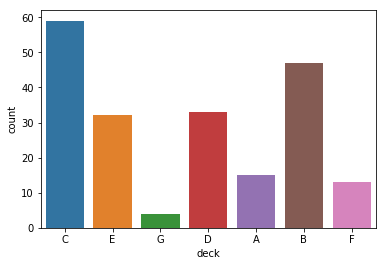

In [24]:
sns.countplot(x='deck',data=titanic)

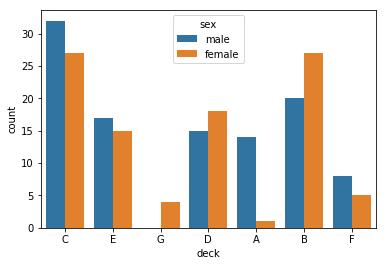

In [25]:
sns.countplot(x='deck',hue='sex',data=titanic)

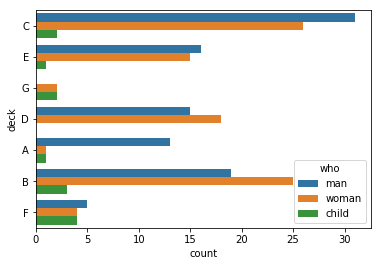

In [26]:
sns.countplot(y='deck',hue='who',data=titanic)

## 4. 散点图

分类散点图。

stripplot() 使用的方法是用少量的随机“抖动”调整分类轴上的点的位置；

swarmplot() 表示的是带分布属性的散点图。

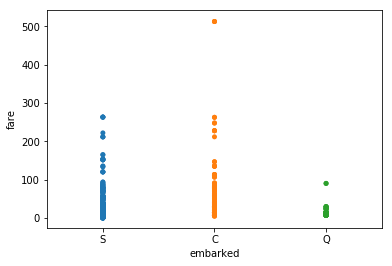

In [27]:
sns.stripplot(x='embarked',y='fare',data=titanic)

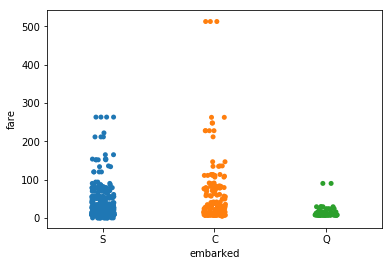

In [29]:
# 设置'jitter'参数控制抖动的大小
sns.stripplot(x='embarked',y='fare',
                    data=titanic,jitter=1)

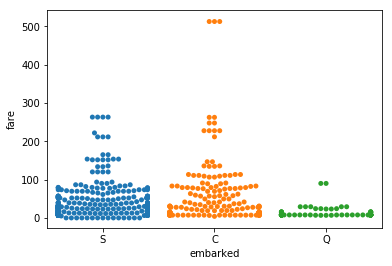

In [30]:
# swarmplot() 方法使用防止它们重叠的算法沿着分类轴调整点。它可以更好地表示观测的分布，它适用于相对较小的数据集。
sns.swarmplot(x='embarked',y='fare',data=titanic)

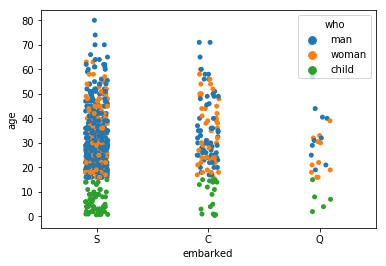

In [31]:
sns.stripplot(x='embarked',y='age',hue='who',jitter=1,data=titanic)

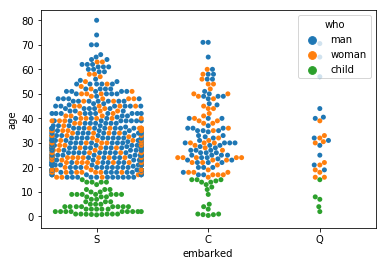

In [32]:
sns.swarmplot(x='embarked',y='age',hue='who',data=titanic)

## 5. 箱线图

显示一组数据分散情况的统计图。它能显示出一组数据的最大值、最小值、中位数及上下四分位数。

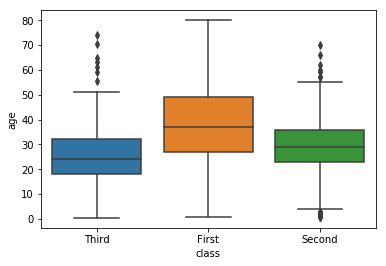

In [33]:
sns.boxplot(x='class',y='age',data=titanic)

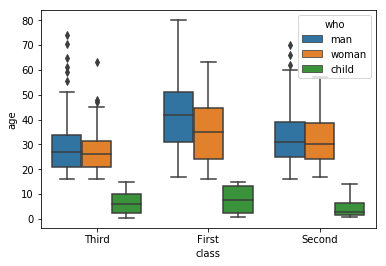

In [34]:
sns.boxplot(x='class',y='age',hue='who',data=titanic)

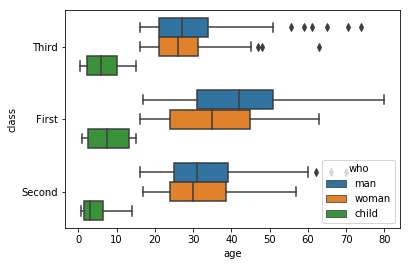

In [35]:
sns.boxplot(x='age',y='class',hue='who',data=titanic)

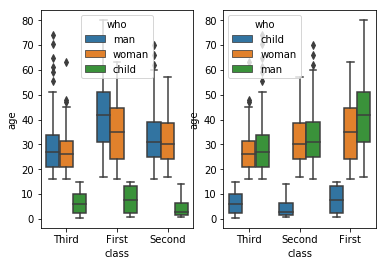

In [36]:
# 调节'order' 和 'hue_order' 参数，我们可以控制x轴展示的顺序。
fig,axes=plt.subplots(1,2) 

sns.boxplot(x='class',y='age',hue='who',
                    data=titanic,ax=axes[0])

sns.boxplot(x='class',y='age',hue='who',data=titanic,
                    order=['Third','Second','First'],
                    hue_order=['child','woman','man'],ax=axes[1])

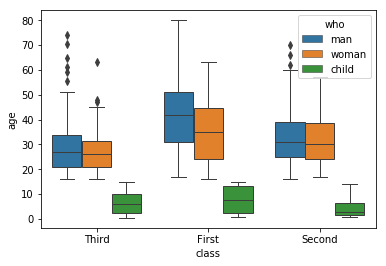

In [37]:
# linewidth 控制线条粗细
sns.boxplot(x='class',y='age',hue='who',
                    linewidth=1,data=titanic)

## 6. 小提琴图

小提琴图其实是箱线图与核密度图的结合，箱线图展示了分位数的位置，小提琴图则展示了任意位置的密度，通过小提琴图可以知道哪些位置的密度较高。

在图中，白点是中位数，黑色盒型的范围是下四分位点到上四分位点，细黑线表示须。外部形状即为核密度估计。

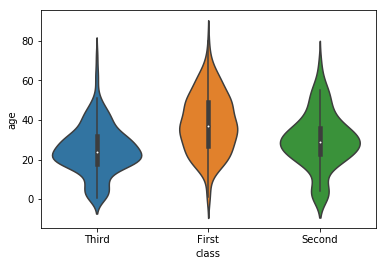

In [38]:
sns.violinplot(x='class',y='age',data=titanic)

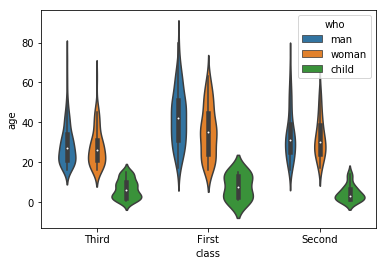

In [40]:
sns.violinplot(x='class',y='age',hue='who',data=titanic)

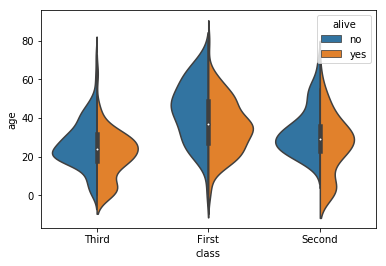

In [41]:
sns.violinplot(x='class',y='age',hue='alive',
                    data=titanic,split=True)

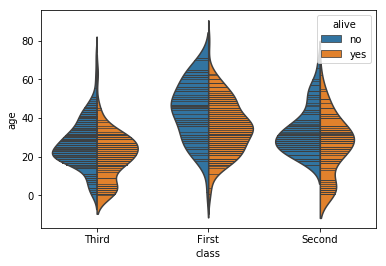

In [44]:
# 在小提琴内部添加图形来帮助我们进行分析，这里就需要控制'inner'参数。
sns.violinplot(x='class',y='age',hue='alive',
                    data=titanic,split=True,inner='stick')

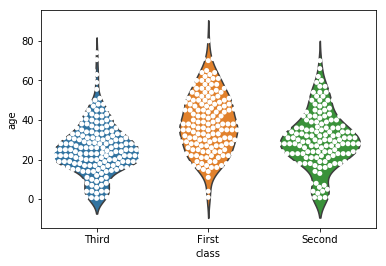

In [45]:
sns.violinplot(x='class',y='age',data=titanic,inner=None)
sns.swarmplot(x='class',y='age',data=titanic,color='white')

## 7. 回归图

利用 regplot() 和 lmplot() 来进行回归，确定线性关系

In [50]:
iris = pd.read_csv('./Iris.csv')
#随机查看数据集的10行数据
iris.sample(10)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
15,16,5.7,4.4,1.5,0.4,Iris-setosa
0,1,5.1,3.5,1.4,0.2,Iris-setosa
64,65,5.6,2.9,3.6,1.3,Iris-versicolor
11,12,4.8,3.4,1.6,0.2,Iris-setosa
112,113,6.8,3.0,5.5,2.1,Iris-virginica
24,25,4.8,3.4,1.9,0.2,Iris-setosa
20,21,5.4,3.4,1.7,0.2,Iris-setosa
135,136,7.7,3.0,6.1,2.3,Iris-virginica
62,63,6.0,2.2,4.0,1.0,Iris-versicolor
48,49,5.3,3.7,1.5,0.2,Iris-setosa


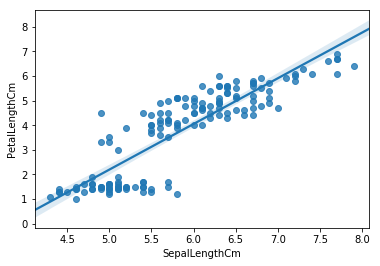

In [52]:
sns.regplot(x='SepalLengthCm',y='PetalLengthCm',data=iris)

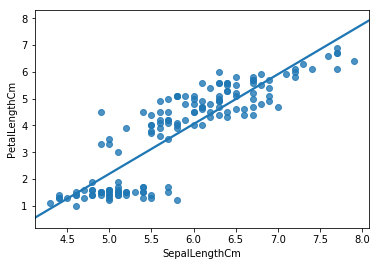

In [54]:
# 关于置信区间，可以通过设置'ci'参数控制是否显示。
sns.regplot(x='SepalLengthCm',y='PetalLengthCm',data=iris,ci=None)

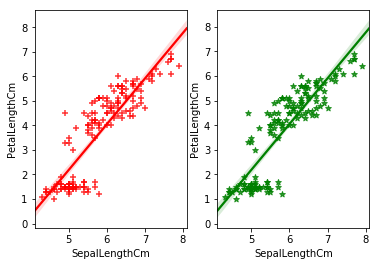

In [56]:
fig,axes=plt.subplots(1,2) 

sns.regplot(x='SepalLengthCm',y='PetalLengthCm',data=iris,
            color='r',marker='+',ax=axes[0])

sns.regplot(x='SepalLengthCm',y='PetalLengthCm',data=iris,
            color='g',marker='*',ax=axes[1])

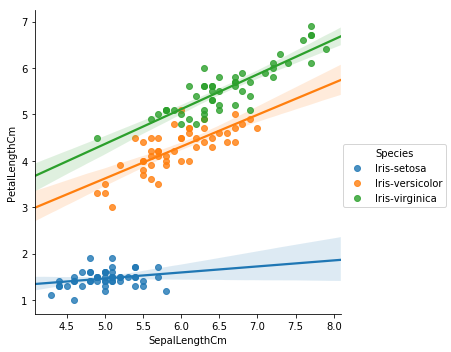

In [58]:
sns.lmplot(x='SepalLengthCm',y='PetalLengthCm',
                 hue='Species',data=iris)

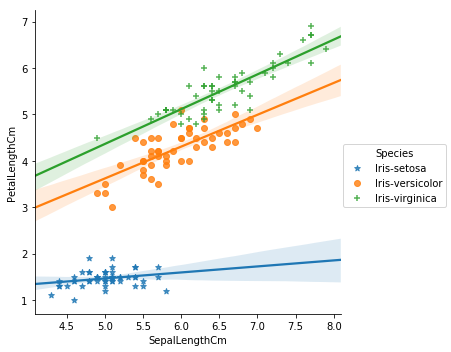

In [59]:
sns.lmplot(x='SepalLengthCm',y='PetalLengthCm',hue='Species',
                    data=iris,markers=['*','o','+'])

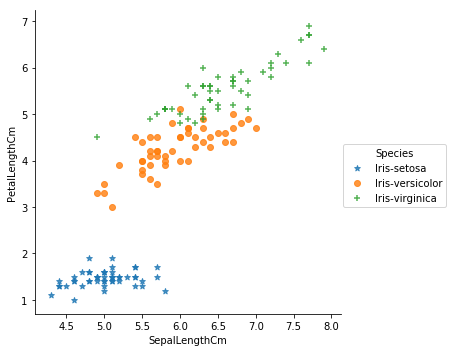

In [60]:
sns.lmplot(x='SepalLengthCm',y='PetalLengthCm',hue='Species',
                data=iris,markers=['*','o','+'],fit_reg=False)

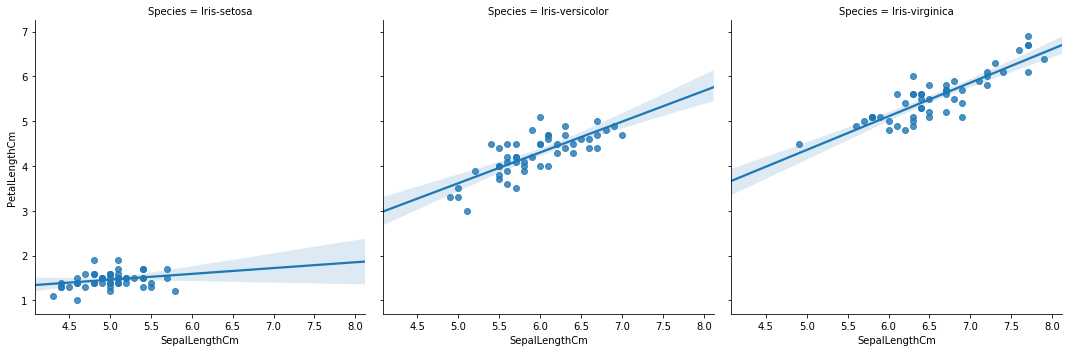

In [61]:
sns.lmplot(x='SepalLengthCm',y='PetalLengthCm',
                col='Species',data=iris)

## 8. 热力图

热力图通常用来表示特征之间的相关性，一般通过颜色的深浅来表示数值的大小或者相关性的高低。

In [63]:
flights  = pd.read_csv('./flights.csv')
#随机查看数据集的10行数据
flights.sample(10)

,year,month,passengers
111,1958,April,348
42,1952,July,230
87,1956,April,313
44,1952,September,209
3,1949,April,129
0,1949,January,112
98,1957,March,356
114,1958,July,491
24,1951,January,145
113,1958,June,435


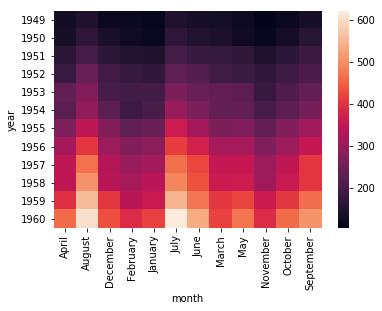

In [64]:
f=flights.pivot('year','month','passengers')
sns.heatmap(f)

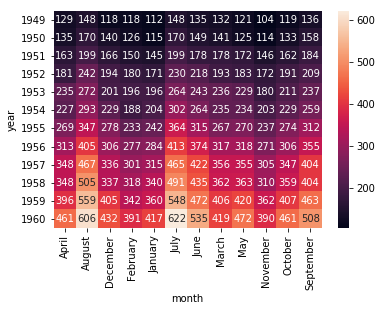

In [65]:
sns.heatmap(f, annot=True,fmt="d")

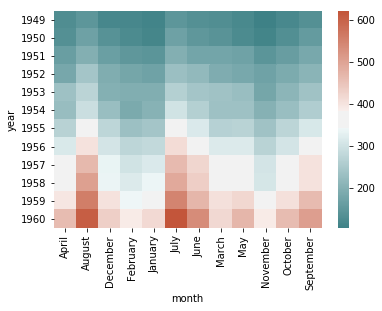

In [66]:
cmap = sns.diverging_palette(200,20,sep=20,as_cmap=True)
sns.heatmap(f,cmap=cmap)